In [1]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
df_DA_IN = df[
    (df['job_country'] == 'India') &
    (df['job_title_short'] == 'Data Analyst')
].copy()

df_DA_IN = df_DA_IN.dropna(subset=['salary_year_avg'])

df_DA_IN['salary_year_avg'].sample(10)

462026    111175.0
758853    111175.0
597416    111175.0
61483     105000.0
305374     79200.0
610349    111175.0
483274    105650.0
763431     79200.0
720328    111175.0
60135      79200.0
Name: salary_year_avg, dtype: float64

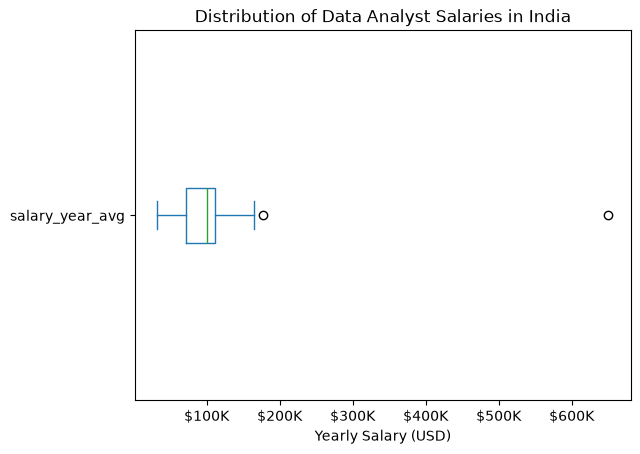

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df_DA_IN['salary_year_avg'].plot(kind='box', vert=False)

plt.title('Distribution of Data Analyst Salaries in India')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('')

ax = plt.gca()
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'${x / 1000:.0f}K')
)

plt.show()

/var/folders/92/n250n5js571gbfb6p9lrnjlm0000gn/T/ipykernel_47642/2005856089.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list, tick_labels=job_titles, vert=False)


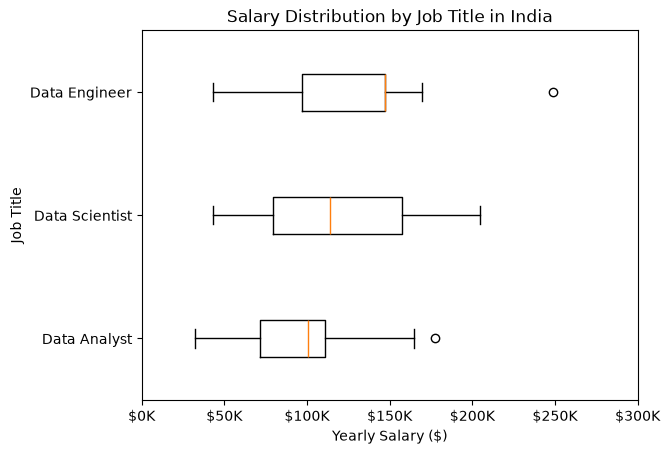

In [21]:
job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer']

df_IN = df[
    (df['job_country'] == 'India') &
    (df['job_title_short'].isin(job_titles))
].copy()

df_IN = df_IN.dropna(subset=['salary_year_avg'])

job_list = [
    df_IN[df_IN['job_title_short'] == job_title]['salary_year_avg']
    for job_title in job_titles
]

plt.boxplot(job_list, tick_labels=job_titles, vert=False)

ax = plt.gca()
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'${x/1000:.0f}K')
)


plt.title('Salary Distribution by Job Title in India')
plt.xlabel('Yearly Salary ($)')
plt.ylabel('Job Title')
plt.xlim(0,300000)
plt.show()